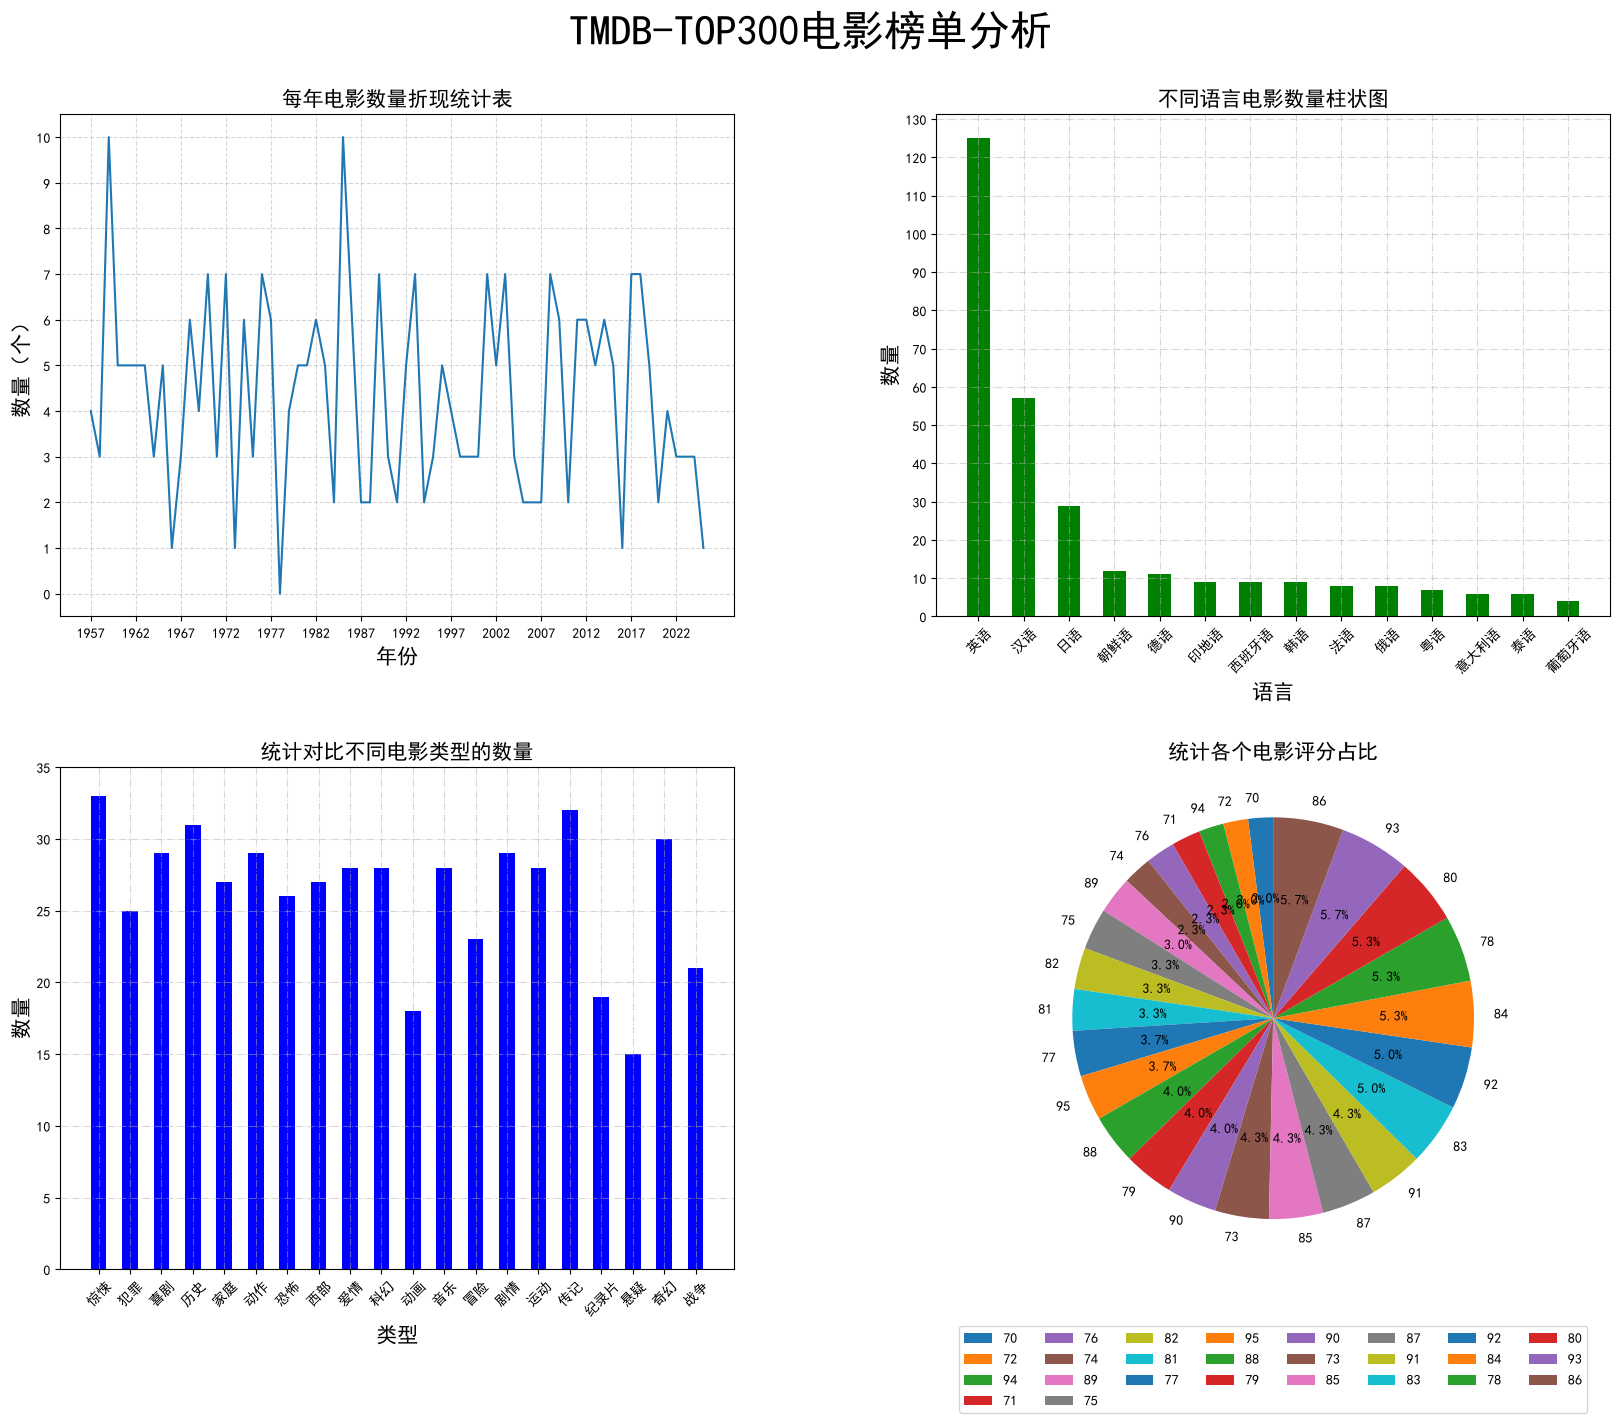

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.pyplot import figure

plt.rcParams['font.sans-serif'] = ['SimHei']#显示中文并显示黑体
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(20,15),dpi=100)
fig.suptitle('TMDB-TOP300电影榜单分析',fontsize=30,x=0.5,y=0.95)#添加大标题，fontsize是控制标题的字体大小，xy是控制标题的位置x是横向 y 是纵轴的位置
fig.subplots_adjust(hspace=0.3,wspace=0.3)
axes1:Axes=ax[0,0]
axes2:Axes=ax[0,1]
axes3:Axes=ax[1,0]
axes4:Axes=ax[1,1]
#读取数据python 10.TMDB-TOP300电影榜单统计分析.py
#int64:整形数据，不支持空值,要让年份不带.0 则要把类型改为Int64的类型
#Int64:整形数据，支持空值
data=pd.read_csv('data/movies.csv',usecols=["电影名","年份","上映时间","类型","时长","评分","语言"],dtype={'年份':'Int64'})#使用usecols来显示需要用的列名，不是所有的列都要用
data
#需求一：统计电影中，每年上映的电影变化，用折线图表示
#1.1 优于抓取的数据可能有年份丢失，所以要进行处理
# print(data.isnull().sum())
data['年份']=data['年份'].fillna(data['上映时间'].str[0:4])#将上映时间的年份剪切给年份，并更新年份
data.head(100)
# data[data['年份']<=0] 检查是否有年份异常值
#进行年份分组
year_count=data.groupby('年份')['年份'].count()
#组装数据 x轴为年份 y轴为数量
#x 轴数据
min_year=year_count.index.min()
max_year=year_count.index.max()
x=[i for i in range(min_year,max_year+1)]#最小值年份，最大值年份
#y周数据
y=[year_count.get(i,0) for i in x]
y
axes1.plot(x,y)
axes1.set_title('每年电影数量折现统计表',fontsize=15)
axes1.set_xlabel('年份',fontsize=15)
axes1.set_xticks(x[::5])
axes1.set_ylabel('数量（个）',fontsize=15)
y_ticks=[i for i in range(0,11,1)]
axes1.set_yticks(y_ticks)
axes1.grid(linestyle='--',alpha=0.5)

#2.需求二：统计对比不同语言的数量 柱状图
language_count=data.groupby('语言')['语言'].count().sort_values(ascending=False)#此时这里是一列带标签的数据，有index 和 values 这两个值
#组装x y 轴的数据
x_language=language_count.index.tolist()#从language_count 中取出索引Index然后将这些名字转换为python的列表
y_language_count=language_count.values.tolist()#从language_count 中取出数据values然后将这些名字转换为python的列表
axes2.bar(x_language,y_language_count,color='green',width=0.5)
axes2.set_title('不同语言电影数量柱状图',fontsize=15)
axes2.set_xlabel('语言',fontsize=15)
axes2.set_ylabel('数量',fontsize=15)
axes2.set_yticks(range(0,131,10))#表示从0 开始 间隔10 到130
axes2.grid(linestyle='-.',alpha=0.5)
axes2.tick_params(axis='x',rotation=45)#可以对轴上的数据进行旋转，比如这里是旋转45°


#统计对比不同类型电影的数量，然后绘制成柱状图
type_count={}#把电影以及对应的数量写成字典的形式
for types in data['类型'].str.split(','):#先把电影类型拆开，也就是types：['惊悚', '犯罪']的类型
    for type in types:#然后再遍历types ，如果type_count中没有这个type 则直接添加，有的话就加1
        if type in type_count:
            type_count[type]+=1
        else:
            type_count[type]=1
x_types=type_count.keys()
y_types=type_count.values()
axes3.bar(x_types,y_types,color='blue',width=0.5)
axes3.set_title('统计对比不同电影类型的数量',fontsize=15)
axes3.set_xlabel('类型',fontsize=15)
axes3.set_ylabel('数量',fontsize=15)
axes3.set_yticks(range(0,40,5))
axes3.grid(linestyle='-.',alpha=0.5)
axes3.tick_params(axis='x',rotation=45)#对x轴的数据旋转45°


#统计对比各个评分的电影占比 用饼状图显示
score_count=data.groupby('评分')['评分'].count().sort_values()#data.groupby('评分')是指把把评分相同的电影分到一组，['评分']	选择每组中的“评分”这一列，然后。count()是统计每组有多少个值，.sort_values(ascending=False)(ascending=False)
#合并小数据 （比例小于2%则被认为是小数据）
total=score_count.sum()
x_score=score_count.index.tolist()
y_score_count=score_count.values.tolist()
axes4.pie(y_score_count,labels=x_score,autopct='%1.1f%%',startangle=90)
axes4.set_title('统计各个电影评分占比',fontsize=15)
axes4.legend(loc='lower center',ncol=8,bbox_to_anchor=(0.5,-0.3),fontsize=10)#展示图例，loc控制图例放的位置，ncol是控制一排展示几个，bb0x_to_anchor是控制图例上下左右位置

plt.savefig('data/TMDB-TOP300.png')
plt.show()